# Correlaciones ruido

In [1]:
spark.sql("SHOW TABLES IN gold").show(100, truncate=False)

ivysettings.xml file not found in HIVE_HOME or HIVE_CONF_DIR,/etc/hive/conf.dist/ivysettings.xml will be used
26/11/25 16:39:50 WARN YarnScheduler: Initial job has not accepted any resources; check your cluster UI to ensure that workers are registered and have sufficient resources
26/11/25 16:40:05 WARN YarnScheduler: Initial job has not accepted any resources; check your cluster UI to ensure that workers are registered and have sufficient resources
26/11/25 16:40:20 WARN YarnScheduler: Initial job has not accepted any resources; check your cluster UI to ensure that workers are registered and have sufficient resources
26/11/25 16:40:35 WARN YarnScheduler: Initial job has not accepted any resources; check your cluster UI to ensure that workers are registered and have sufficient resources


+---------+----------------+-----------+
|namespace|tableName       |isTemporary|
+---------+----------------+-----------+
|gold     |aire            |false      |
|gold     |dim_contaminante|false      |
|gold     |dim_distrito    |false      |
|gold     |dim_espira      |false      |
|gold     |dim_estacion    |false      |
|gold     |dim_sonometro   |false      |
|gold     |dim_tiempo      |false      |
|gold     |fact_aire       |false      |
|gold     |fact_meteo      |false      |
|gold     |fact_poblacion  |false      |
|gold     |fact_prediccion |false      |
|gold     |fact_ruido      |false      |
|gold     |fact_trafico    |false      |
|gold     |fact_zona_verde |false      |
+---------+----------------+-----------+



In [2]:
for tabla in [
    "fact_ruido",
    "fact_trafico",
    "fact_aire",
    "dim_sonometro",
    "dim_estacion",
    "dim_tiempo"]:
    print(f"\n--- {tabla} ---")
    spark.table(f"gold.{tabla}").printSchema()


--- fact_ruido ---
root
 |-- id_tiempo: integer (nullable = true)
 |-- id_sonometro: string (nullable = true)
 |-- id_distrito: integer (nullable = true)
 |-- nivel_ruido_db: double (nullable = true)


--- fact_trafico ---
root
 |-- id_tiempo: integer (nullable = true)
 |-- id_espira: string (nullable = true)
 |-- id_distrito: integer (nullable = true)
 |-- intensidad: double (nullable = true)


--- fact_aire ---
root
 |-- id_tiempo: integer (nullable = true)
 |-- id_estacion: string (nullable = true)
 |-- id_contaminante: integer (nullable = true)
 |-- id_distrito: integer (nullable = true)
 |-- concentracion: double (nullable = true)


--- dim_sonometro ---
root
 |-- id_sonometro: string (nullable = true)
 |-- red: string (nullable = true)
 |-- latitud: double (nullable = true)
 |-- longitud: double (nullable = true)
 |-- id_distrito: integer (nullable = true)


--- dim_estacion ---
root
 |-- id_estacion: string (nullable = true)
 |-- codigo_eea: string (nullable = true)
 |-- nombre

In [3]:
# comprobamos cobertura temporal y espacial
for tabla in ["fact_ruido", "fact_trafico", "fact_aire"]:
    print(f"\n--- {tabla} ---")

    spark.sql(f"""
        SELECT
            MIN(t.fecha_hora) AS fecha_inicio,
            MAX(t.fecha_hora) AS fecha_fin,
            COUNT(*) AS registros,
            COUNT(DISTINCT f.id_distrito) AS distritos
        FROM gold.{tabla} f
        JOIN gold.dim_tiempo t
            ON f.id_tiempo = t.id_tiempo
    """).show(truncate=False)


--- fact_ruido ---


+-------------------+-------------------+---------+---------+
|fecha_inicio       |fecha_fin          |registros|distritos|
+-------------------+-------------------+---------+---------+
|2024-01-08 08:00:00|2025-12-31 23:00:00|905090   |16       |
+-------------------+-------------------+---------+---------+


--- fact_trafico ---


+-------------------+-------------------+---------+---------+
|fecha_inicio       |fecha_fin          |registros|distritos|
+-------------------+-------------------+---------+---------+
|2023-03-09 16:00:00|2025-09-23 23:00:00|11637477 |18       |
+-------------------+-------------------+---------+---------+


--- fact_aire ---


+-------------------+-------------------+---------+---------+
|fecha_inicio       |fecha_fin          |registros|distritos|
+-------------------+-------------------+---------+---------+
|2013-01-01 01:00:00|2026-01-01 00:00:00|2215570  |7        |
+-------------------+-------------------+---------+---------+



In [4]:
# Ruido medio por distrito y hora
spark.sql("""
CREATE OR REPLACE TEMP VIEW ruido_horario AS
SELECT id_tiempo, id_distrito,
       AVG(nivel_ruido_db) AS ruido
FROM gold.fact_ruido
WHERE nivel_ruido_db IS NOT NULL
GROUP BY id_tiempo, id_distrito
""")

# Tráfico medio por distrito y hora
spark.sql("""
CREATE OR REPLACE TEMP VIEW trafico_horario AS
SELECT id_tiempo, id_distrito,
       AVG(intensidad) AS trafico
FROM gold.fact_trafico
WHERE intensidad IS NOT NULL
GROUP BY id_tiempo, id_distrito
""")

# Unimos ruido y tráfico
spark.sql("""
CREATE OR REPLACE TEMP VIEW ruido_trafico AS
SELECT r.id_tiempo, r.id_distrito,
       r.ruido, t.trafico
FROM ruido_horario r
INNER JOIN trafico_horario t
ON r.id_tiempo = t.id_tiempo
AND r.id_distrito = t.id_distrito
""")

# Comprobamos los registros coincidentes
spark.sql("""
SELECT COUNT(*) AS registros,
       COUNT(DISTINCT id_distrito) AS distritos
FROM ruido_trafico
""").show()

+---------+---------+
|registros|distritos|
+---------+---------+
|    48255|       15|
+---------+---------+



In [5]:
from pyspark.sql import functions as F
from pyspark.sql.window import Window

datos = spark.table("ruido_trafico")

# Correlación de Pearson
pearson = datos.stat.corr("ruido", "trafico")

# Correlación de Spearman mediante rangos
w_ruido = Window.orderBy("ruido")
w_trafico = Window.orderBy("trafico")

datos_rangos = (datos
    .withColumn("rango_ruido", F.percent_rank().over(w_ruido))
    .withColumn("rango_trafico", F.percent_rank().over(w_trafico)))

spearman = datos_rangos.stat.corr(
    "rango_ruido", "rango_trafico")

print("Correlación Pearson:", round(pearson, 3))
print("Correlación Spearman:", round(spearman, 3))

26/11/25 16:45:12 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/25 16:45:12 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/25 16:45:12 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/25 16:45:12 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/25 16:45:12 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/25 16:45:13 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/25 1

Correlación Pearson: 0.459
Correlación Spearman: 0.525


In [6]:
from pyspark.sql import functions as F

correlaciones_distrito = (spark.table("ruido_trafico")
    .groupBy("id_distrito")
    .agg(F.count("*").alias("registros"),
        F.corr("ruido", "trafico").alias("pearson"))
    .orderBy("id_distrito"))

correlaciones_distrito.show(20, truncate=False)

+-----------+---------+-------------------+
|id_distrito|registros|pearson            |
+-----------+---------+-------------------+
|1          |5519     |0.5358901745070959 |
|2          |3867     |0.6484920507211707 |
|3          |5544     |0.6484413384582941 |
|4          |2616     |0.6273238916371694 |
|5          |1450     |0.36876379106661683|
|6          |5594     |0.624402461410818  |
|7          |10       |0.2867709617559694 |
|9          |1828     |0.7039335274636964 |
|10         |2621     |0.7073271617394864 |
|11         |2620     |0.6410408603124892 |
|12         |1964     |0.6240041324064232 |
|13         |5632     |0.4241352299775849 |
|14         |3805     |0.46147408614898466|
|15         |2576     |0.6685302013177561 |
|18         |2609     |0.5113116649020583 |
+-----------+---------+-------------------+



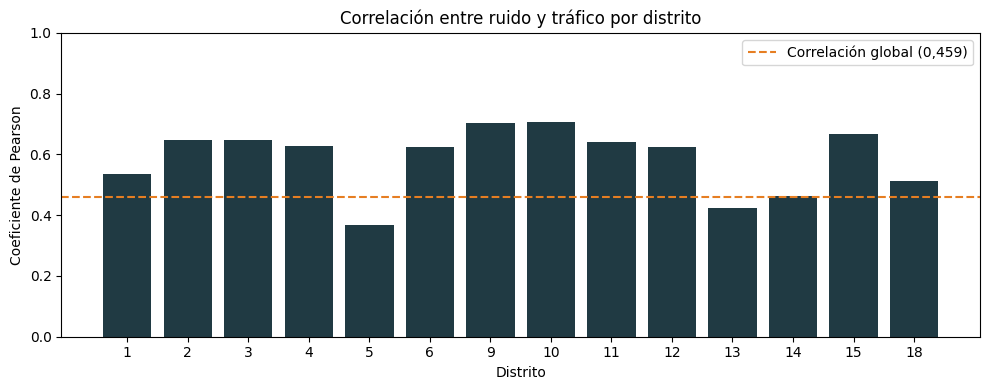

In [7]:
import matplotlib.pyplot as plt
from google.cloud import storage

# Resultados por distrito
df = correlaciones_distrito.filter("registros >= 100").toPandas()

plt.figure(figsize=(10, 4))
plt.bar(df["id_distrito"].astype(str), df["pearson"],
        color="#203A43")

plt.axhline(0.459, color="#E67E22", linestyle="--",
            label="Correlación global (0,459)")

plt.title("Correlación entre ruido y tráfico por distrito")
plt.xlabel("Distrito")
plt.ylabel("Coeficiente de Pearson")
plt.ylim(0, 1)
plt.legend()
plt.tight_layout()

# Guardar y subir al bucket
ruta = "/tmp/correlacion_ruido_trafico.png"
plt.savefig(ruta, dpi=300, bbox_inches="tight")
plt.show()

storage.Client().bucket("tfm_unir1").blob(
    "figuras/correlacion_ruido_trafico.png"
).upload_from_filename(ruta)

## Correlación entre ruido y contaminación atmosférica

In [8]:
# Comprobar los contaminantes disponibles
spark.sql("""
SELECT id_contaminante, nombre
FROM gold.dim_contaminante
ORDER BY id_contaminante
""").show(truncate=False)

# Comprobar coincidencias entre ruido y aire
spark.sql("""
SELECT
    c.nombre AS contaminante,
    COUNT(*) AS registros,
    COUNT(DISTINCT r.id_distrito) AS distritos
FROM ruido_horario r
JOIN gold.fact_aire a
    ON r.id_tiempo = a.id_tiempo
    AND r.id_distrito = a.id_distrito
JOIN gold.dim_contaminante c
    ON a.id_contaminante = c.id_contaminante
WHERE a.concentracion IS NOT NULL
GROUP BY c.nombre
ORDER BY c.nombre
""").show(truncate=False)

+---------------+------+
|id_contaminante|nombre|
+---------------+------+
|5              |PM10  |
|7              |O3    |
|8              |NO2   |
|6001           |PM2.5 |
+---------------+------+



+------------+---------+---------+
|contaminante|registros|distritos|
+------------+---------+---------+
|NO2         |47062    |6        |
|O3          |40270    |6        |
|PM10        |39598    |4        |
|PM2.5       |39468    |4        |
+------------+---------+---------+



In [9]:
from pyspark.sql import functions as F
from pyspark.sql.window import Window

# Concentración media por distrito, hora y contaminante
aire_horario = spark.sql("""
    SELECT
        a.id_tiempo,
        a.id_distrito,
        c.nombre AS contaminante,
        AVG(a.concentracion) AS concentracion
    FROM gold.fact_aire a
    JOIN gold.dim_contaminante c
        ON a.id_contaminante = c.id_contaminante
    WHERE a.concentracion IS NOT NULL
      AND c.nombre IN ('NO2', 'O3', 'PM10', 'PM2.5')
    GROUP BY a.id_tiempo, a.id_distrito, c.nombre
""")

# Unión con el ruido
ruido_aire = (spark.table("ruido_horario")
    .join(aire_horario, ["id_tiempo", "id_distrito"])
    .filter(F.col("ruido").isNotNull()))

ruido_aire.createOrReplaceTempView("ruido_aire")

# Correlaciones
resultados = []

for contaminante in ["NO2", "O3", "PM10", "PM2.5"]:
    datos = ruido_aire.filter(F.col("contaminante") == contaminante)

    pearson = datos.stat.corr("ruido", "concentracion")

    # Spearman con rangos promedio para empates
    w_ruido = Window.orderBy("ruido")
    w_aire = Window.orderBy("concentracion")

    rangos = (datos
        .withColumn("r_ruido", F.cume_dist().over(w_ruido))
        .withColumn("r_aire", F.cume_dist().over(w_aire)))

    spearman = rangos.stat.corr("r_ruido", "r_aire")

    resultados.append((contaminante,datos.count(),
        round(pearson, 3),round(spearman, 3)))

for resultado in resultados:
    print(resultado)

26/11/25 16:49:38 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/25 16:49:38 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/25 16:49:38 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/25 16:49:38 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/25 16:49:38 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/25 16:49:39 WARN WindowExec: No Partition Defined for Window operation! Moving all data to a single partition, this can cause serious performance degradation.
26/11/25 1

('NO2', 40816, 0.023, 0.005)
('O3', 40270, 0.223, 0.236)
('PM10', 33353, 0.009, -0.03)
('PM2.5', 33341, -0.058, -0.084)


In [10]:
from pyspark.sql import functions as F

correlaciones_aire_distrito = (ruido_aire
    .groupBy("contaminante", "id_distrito")
    .agg(F.count("*").alias("registros"),
        F.corr("ruido", "concentracion").alias("pearson"))
    .orderBy("contaminante", "id_distrito"))

correlaciones_aire_distrito.show(100, truncate=False)


+------------+-----------+---------+--------------------+
|contaminante|id_distrito|registros|pearson             |
+------------+-----------+---------+--------------------+
|NO2         |4          |5691     |0.13483679468788895 |
|NO2         |5          |4006     |0.12849920396490155 |
|NO2         |9          |4222     |0.1392729923961536  |
|NO2         |10         |6475     |0.3143289719807418  |
|NO2         |12         |4511     |0.15352235165900838 |
|NO2         |13         |15911    |-0.06337416959167062|
|O3          |4          |6084     |0.25424188790051605 |
|O3          |5          |3951     |0.2600912535728388  |
|O3          |9          |4352     |0.2139962595633795  |
|O3          |10         |5822     |0.019016527196331453|
|O3          |12         |4394     |0.1498792415913297  |
|O3          |13         |15667    |0.3282252658104537  |
|PM10        |4          |6219     |0.03935972724899301 |
|PM10        |10         |6480     |0.15175807522997178 |
|PM10        |

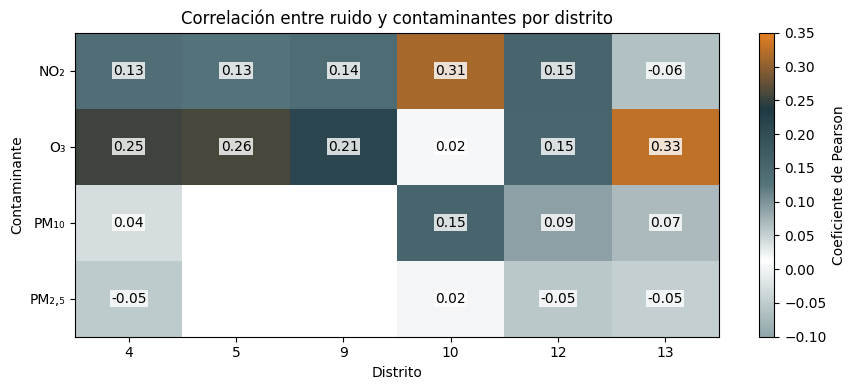

In [19]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from google.cloud import storage

df = correlaciones_aire_distrito.toPandas()

matriz = df.pivot(index="contaminante",columns="id_distrito",
    values="pearson").reindex(["NO2", "O3", "PM10", "PM2.5"])

# Paleta del TFM
colores = ["#8FA5A8", "#FFFFFF", "#56747B", "#203A43", "#E67E22"]
cmap = LinearSegmentedColormap.from_list("paleta_tfm", colores)
cmap.set_bad("white")

fig, ax = plt.subplots(figsize=(9, 4))
im = ax.imshow(matriz, cmap=cmap, aspect="auto",
               vmin=-0.1, vmax=0.35)

ax.set_xticks(range(len(matriz.columns)))
ax.set_xticklabels(matriz.columns)
ax.set_yticks(range(len(matriz.index)))
ax.set_yticklabels(["NO₂", "O₃", "PM₁₀", "PM₂,₅"])

# Escribir todos los valores manualmente
for i in range(len(matriz.index)):
    for j in range(len(matriz.columns)):
        valor = matriz.iloc[i, j]
        if pd.notna(valor):
            ax.text(j, i, f"{valor:.2f}",
                    ha="center", va="center",
                    color="black", fontsize=10,
                    bbox=dict(facecolor="white",
                              alpha=0.8, edgecolor="none",
                              pad=1))

ax.set_title("Correlación entre ruido y contaminantes por distrito")
ax.set_xlabel("Distrito")
ax.set_ylabel("Contaminante")

fig.colorbar(im, ax=ax, label="Coeficiente de Pearson")
plt.tight_layout()

ruta = "/tmp/correlacion_ruido_aire.png"
plt.savefig(ruta, dpi=300, bbox_inches="tight")
plt.show()

storage.Client().bucket("tfm_unir1").blob(
    "figuras/correlacion_ruido_aire.png"
).upload_from_filename(ruta)